# PreSelect: documentos e resultados dos seis modelos

Abra este notebook e use **Run All / Executar tudo**. A análise é local, usa os resultados já calculados
e não precisa de GPU, conexão com a internet ou pesos de modelos. As saídas já estão salvas para leitura.

Vamos conferir a integridade, ver os textos, comparar as capacidades e os BPCs e descrever a força preditiva.
São os mesmos 1.000 documentos em duas execuções: quatro modelos iniciais e dois adicionais.
Não há análise semântica nem classificação dos textos como “bons” ou “ruins”.

In [1]:
from pathlib import Path
import sys, json, hashlib, html, itertools
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'dados/consolidado/documentos_forca_preditiva.jsonl').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook dentro da pasta entrega extraída, mantendo dados/ ao lado de notebooks/.')
DATA = ROOT / 'dados/consolidado'
FIGURES = ROOT / 'docs/figuras'
FIGURES.mkdir(parents=True, exist_ok=True)
df = pd.DataFrame(json.loads(line) for line in (DATA / 'documentos_forca_preditiva.jsonl').read_bytes().splitlines())
reports = json.loads((DATA / 'ranking_e_benchmarks.json').read_text(encoding='utf-8'))
models = sorted(reports, key=lambda model: reports[model]['benchmark']['score'])
bpc_columns = ['bpc__' + model for model in models]
short = {model: model.split('/')[-1] for model in models}
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(df):,} documentos | {df.domain.nunique()} domínios | {len(models)} modelos | {df[bpc_columns].count().sum():,} BPCs')

1,000 documentos | 50 domínios | 6 modelos | 6,000 BPCs


## 1. Conferência dos resultados

Esta célula valida os seis ZIPs originais, recibos, textos, checkpoints, contagens dos benchmarks e
cobertura dos tokens. Também recalcula a força a partir dos ZIPs e compara com o consolidado entregue.

In [2]:
sys.path.insert(0, str(ROOT / 'src'))
from verificar import verify
verification = verify(ROOT)
print('Integridade:', verification['status'])
print('Pares comparáveis por documento:', verification['comparable_pairs_per_document'])
display(pd.DataFrame([{'documentos': len(df), 'domínios': df.domain.nunique(),
                      'IDs duplicados': int(df.document_id.duplicated().sum()),
                      'textos repetidos por hash': int(df.text_sha256.duplicated().sum()),
                      'BPCs ausentes': int(df[bpc_columns].isna().sum().sum()),
                      'caracteres totais': int(df.n_chars.sum())}]))

Unificação concluída: 1000 documentos × 6 modelos.
C:\Users\gusta\AppData\Local\Temp\tmp75rc70rn\recomputed.zip
Integridade: validado
Pares comparáveis por documento: [15]


,documentos,domínios,IDs duplicados,textos repetidos por hash,BPCs ausentes,caracteres totais
0,1000,50,0,4,0,3610511


## 2. Ver os documentos

A tabela mostra uma prévia. Ajuste os filtros abaixo e execute novamente esta célula.
`BUSCA` procura uma sequência literal no texto; não é uma comparação semântica.

In [3]:
DOMINIO = ''           # Exemplo: copie um domínio da tabela; vazio inclui todos.
BUSCA = ''             # Texto literal; vazio inclui todos.
FORCA_MINIMA = 0.0
FORCA_MAXIMA = 1.0

selection = df.loc[df.predictive_strength.between(FORCA_MINIMA, FORCA_MAXIMA)].copy()
if DOMINIO:
    selection = selection[selection.domain.eq(DOMINIO)]
if BUSCA:
    selection = selection[selection.text.str.contains(BUSCA, case=False, regex=False, na=False)]
selection = selection.sort_values(['predictive_strength', 'document_id'], ascending=[False, True]).reset_index(drop=True)
preview = selection[['document_id', 'domain', 'n_chars', 'predictive_strength', 'concordant_pairs']].copy()
preview['trecho'] = selection.text.str.replace(r'\s+', ' ', regex=True).str.slice(0, 180)
print(f'{len(selection)} documentos encontrados. Mostrando os primeiros 15:')
display(preview.head(15))

1000 documentos encontrados. Mostrando os primeiros 15:


,document_id,domain,n_chars,predictive_strength,concordant_pairs,trecho
0,01600b839cb7f2f5e54a35b12b2f7033554cdd79e3d21506b30269e6c31adc14,www.meetup.com,566,1.0,15,"Jennifer G. Anchorage, AK Member since: March 13, 2013 Are you a current member of ASTD (nationa..."
1,037847158804e452b4a78848a2de2e103a1f9c8df81db3ee00b381e62863d0d0,www.popmatters.com,7052,1.0,15,"Sweet Land by Matt Mazur 7 August 2007 For wearing the disguise of an underground, independent A..."
2,0549e8e43fd3255f9702ba5049b6706f4aff7484f56fab2920a65b6098600a06,www.theregister.co.uk,2057,1.0,15,"Microsoft issues emergency IE patch as attacks escalate Patch now In many cases, the websites di..."
3,06bf61fddbf1e60fda4cc1e56df19a149f570a4b01c0d4e00ef5e8531a6d0739,www.theguardian.com,3105,1.0,15,"Radical ruling proposed on food advertising Fruit and veg: under the proposed ruling, only fresh..."
4,07eaa4ff3d2ee9b13b4454fdef99f63f2f315db0128d4bc4db2e88af13b21caa,www.upi.com,1223,1.0,15,"Limbless swimmer completes feat Aug. 18, 2012 at 11:35 PM DIOMEDE, Alaska, Aug. 18 (UPI) -- Fren..."
5,0a2f9d5f9ebff1316d4be19d42b8c16466c844295b3638ae92b5e47c9025f98d,www.hindustantimes.com,401,1.0,15,"Petrol price hike on cards Updated: January 02, 2012 14:01 IST Oil companies are set to meet tod..."
6,0b7942d50524c79a28652a96de06c91c276470591116f6754596acb54cd4fc2a,www.bbc.co.uk,4465,1.0,15,"Entertainment & Arts Rik Mayall, star of The Young Ones, dies aged 56 Rik Mayall Image copyright..."
7,0bbac3bd1455eb5047cf6f7e81fb3a02596ec050609c9bf7d4a5e625bad830c8,phys.org,357,1.0,15,News tagged with judgments Data presentation and consumer confidence Is it better to present dat...
8,0bcdc86df26bec42c3f59602404898757fc3c481e12ec3ae0d554183297fdf35,bleacherreport.com,2680,1.0,15,Jeremy Lin Must Earn 2014 All-Star Spot to Justify Contract Use your ← → (arrow) keys to browse ...
9,0cdfd21668036a089535f1bc227bed426fa3dea3a7b65fe3f734f27013e42ee5,www.osnews.com,1217,1.0,15,Permalink for comment 88304 Geometry bug by ozonehole on Sun 22nd Jan 2006 03:58 UTC Member sin...


In [4]:
POSICAO = 0            # Posição na seleção acima, começando em zero.
DOCUMENT_ID = ''        # Opcional: ID completo; substitui a escolha por posição.

def mostrar_documento(row):
    display(pd.DataFrame([{key: row[key] for key in
                         ['document_id', 'domain', 'url', 'n_chars', 'concordant_pairs', 'comparable_pairs', 'predictive_strength']}]))
    display(pd.DataFrame({'modelo': [short[m] for m in models],
                          'BPC': [row['bpc__' + m] for m in models]}))
    # Escape HTML para mostrar o texto como dado, sem executar conteúdo do corpus.
    display(HTML('<div style="white-space:pre-wrap;overflow-wrap:anywhere;border:1px solid #ccc;'
                 'padding:16px;max-height:650px;overflow:auto">' + html.escape(row['text']) + '</div>'))

if DOCUMENT_ID:
    chosen = df[df.document_id.eq(DOCUMENT_ID)]
    if chosen.empty:
        print('ID não encontrado.')
    else:
        mostrar_documento(chosen.iloc[0])
elif 0 <= POSICAO < len(selection):
    mostrar_documento(selection.iloc[POSICAO])
else:
    print('Nenhum documento nessa posição. Ajuste os filtros ou POSICAO.')

,document_id,domain,url,n_chars,concordant_pairs,comparable_pairs,predictive_strength
0,01600b839cb7f2f5e54a35b12b2f7033554cdd79e3d21506b30269e6c31adc14,www.meetup.com,http://www.meetup.com/ASTD-Alaska/members/84615562/,566,15,15,1.0


,modelo,BPC
0,pythia-160m-deduped,1.498738
1,pythia-410m-deduped,1.155837
2,pythia-1b-deduped,1.059960
3,pythia-1.4b-deduped,1.044765
4,gpt-neo-1.3B,1.033991
5,gpt-neo-2.7B,1.013990


## 3. Capacidade dos modelos e BPC

Capacidade é a média simples de HellaSwag (`acc_norm`), ARC-Easy (`acc_norm`) e BoolQ (`acc`),
com avaliação completa e zero-shot. Os números abaixo são proporções de acerto, entre 0 e 1.
**BPC menor significa que o modelo previu melhor aquele texto.**
A ordem dos modelos é definida pela capacidade medida, não pelo número de parâmetros.

,modelo,capacidade,hellaswag,arc_easy,boolq,BPC médio,BPC mediano,BPC p10,BPC p90
0,pythia-160m-deduped,0.3490,0.2979,0.3573,0.3917,1.5354,1.4885,1.2077,1.9035
1,pythia-410m-deduped,0.4501,0.3975,0.4242,0.5284,1.1553,1.1136,0.8879,1.4517
2,pythia-1b-deduped,0.5341,0.4861,0.5143,0.6018,1.0355,0.9976,0.7772,1.3248
3,pythia-1.4b-deduped,0.5359,0.5292,0.5488,0.5297,1.0367,0.9967,0.7806,1.3234
4,gpt-neo-1.3B,0.5379,0.4887,0.5034,0.6217,1.0303,0.9950,0.7679,1.3211
5,gpt-neo-2.7B,0.5703,0.5526,0.5379,0.6205,0.9924,0.9543,0.7354,1.2739


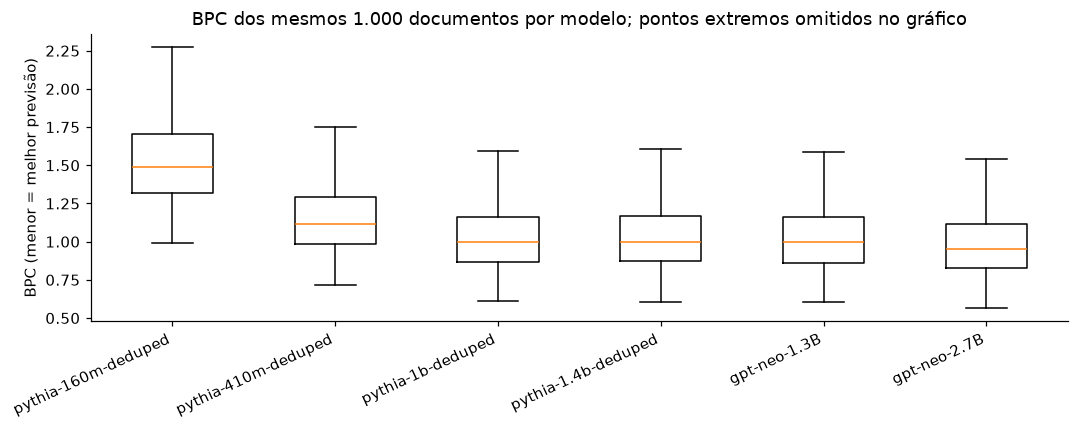

In [5]:
model_rows = []
for model in models:
    benchmark = reports[model]['benchmark']
    values = df['bpc__' + model]
    model_rows.append({'modelo': short[model], 'capacidade': benchmark['score'],
                      **benchmark['per_task'], 'BPC médio': values.mean(),
                      'BPC mediano': values.median(), 'BPC p10': values.quantile(.1),
                      'BPC p90': values.quantile(.9)})
model_table = pd.DataFrame(model_rows)
display(model_table.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df['bpc__' + m] for m in models], showfliers=False)
ax.set_xticks(range(1, len(models) + 1), [short[m] for m in models], rotation=25, ha='right')
ax.set_ylabel('BPC (menor = melhor previsão)')
ax.set_title('BPC dos mesmos 1.000 documentos por modelo; pontos extremos omitidos no gráfico')
fig.tight_layout()
fig.savefig(FIGURES / 'bpc_por_modelo.png', dpi=160, bbox_inches='tight')
plt.show()

## 4. Distribuição da força preditiva

Para cada par de modelos, verificamos se o modelo com maior capacidade também tem BPC menor.
A força é a fração desses pares que concordam. Aqui há 15 pares: `15/15 = 1`, `14/15 ≈ 0,933` etc.
Empates de capacidade seriam excluídos; empate de BPC não conta como concordância.
Força alta indica concordância entre essas ordenações, não uma medida direta de qualidade semântica.

,concordant_pairs,comparable_pairs,documentos,força,percentual
0,9,15,3,0.600,0.3
1,10,15,6,0.667,0.6
2,11,15,11,0.733,1.1
3,12,15,113,0.800,11.3
4,13,15,260,0.867,26.0
5,14,15,411,0.933,41.1
6,15,15,196,1.000,19.6


,predictive_strength,n_chars
count,1000.000,1000.000
mean,0.909,3610.511
std,0.068,6336.739
min,0.600,184.000
25%,0.867,1102.500
50%,0.933,2197.500
75%,0.933,4287.750
max,1.000,143113.000


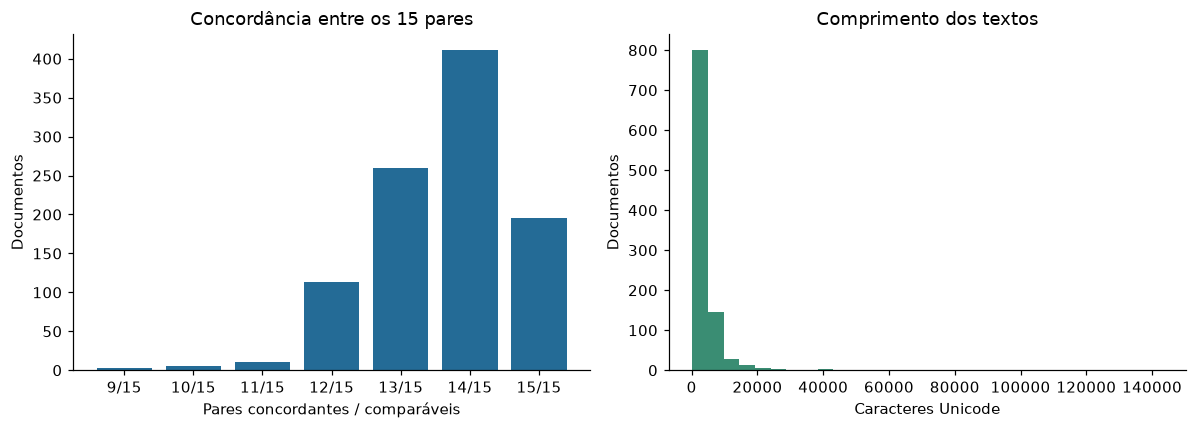

In [6]:
distribution = (df.groupby(['concordant_pairs', 'comparable_pairs'])
                  .size().rename('documentos').reset_index())
distribution['força'] = distribution.concordant_pairs / distribution.comparable_pairs
distribution['percentual'] = 100 * distribution.documentos / len(df)
display(distribution.round(3))
display(df[['predictive_strength', 'n_chars']].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = [f'{a}/{b}' for a, b in zip(distribution.concordant_pairs, distribution.comparable_pairs)]
axes[0].bar(labels, distribution.documentos, color='#246b96')
axes[0].set(title='Concordância entre os 15 pares', xlabel='Pares concordantes / comparáveis', ylabel='Documentos')
axes[1].hist(df.n_chars, bins=30, color='#3a8d73')
axes[1].set(title='Comprimento dos textos', xlabel='Caracteres Unicode', ylabel='Documentos')
fig.tight_layout()
fig.savefig(FIGURES / 'forca_e_comprimento.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Quais pares discordam e como os domínios se distribuem?

“Não concordantes” inclui inversões de BPC e empates exatos. Cada linha compara os mesmos 1.000 textos.
Os resumos por domínio são descritivos; a amostra tem apenas 20 documentos por domínio e não permite
generalizar estas médias para toda a web.

In [7]:
pair_rows = []
for weak, strong in itertools.combinations(models, 2):
    if reports[weak]['benchmark']['score'] == reports[strong]['benchmark']['score']:
        continue
    concordant = df['bpc__' + weak] > df['bpc__' + strong]
    ties = df['bpc__' + weak] == df['bpc__' + strong]
    pair_rows.append({'menor capacidade': short[weak], 'maior capacidade': short[strong],
                      'concordantes': int(concordant.sum()), 'não concordantes': int((~concordant).sum()),
                      'empates de BPC': int(ties.sum()), 'concordância (%)': 100 * concordant.mean()})
pair_table = pd.DataFrame(pair_rows).sort_values('não concordantes', ascending=False)
display(pair_table.round(2))

domain_table = df.groupby('domain').agg(documentos=('document_id', 'size'),
    força_média=('predictive_strength', 'mean'), caracteres_medianos=('n_chars', 'median'))
domain_table = domain_table.sort_values(['força_média', 'domain'], ascending=[False, True])
print('Cinco maiores e cinco menores médias observadas, entre os 50 domínios:')
display(pd.concat([domain_table.head(5), domain_table.tail(5)]).round(3))
length_correlation = df.n_chars.rank().corr(df.predictive_strength.rank())
print(f'Correlação descritiva por postos entre comprimento e força: {length_correlation:.3f}')

,menor capacidade,maior capacidade,concordantes,não concordantes,empates de BPC,concordância (%)
9,pythia-1b-deduped,pythia-1.4b-deduped,439,561,0,43.9
10,pythia-1b-deduped,gpt-neo-1.3B,640,360,0,64.0
12,pythia-1.4b-deduped,gpt-neo-1.3B,663,337,0,66.3
14,gpt-neo-1.3B,gpt-neo-2.7B,965,35,0,96.5
11,pythia-1b-deduped,gpt-neo-2.7B,966,34,0,96.6
13,pythia-1.4b-deduped,gpt-neo-2.7B,967,33,0,96.7
5,pythia-410m-deduped,pythia-1b-deduped,999,1,0,99.9
8,pythia-410m-deduped,gpt-neo-2.7B,999,1,0,99.9
4,pythia-160m-deduped,gpt-neo-2.7B,1000,0,0,100.0
6,pythia-410m-deduped,pythia-1.4b-deduped,1000,0,0,100.0


Cinco maiores e cinco menores médias observadas, entre os 50 domínios:


,documentos,força_média,caracteres_medianos
domain,,,
gizmodo.com,20,0.960,942.5
www.ncbi.nlm.nih.gov,20,0.953,1934.0
gawker.com,20,0.950,1333.0
www.bbc.co.uk,20,0.950,2307.5
www.washingtonpost.com,20,0.950,3809.5
lists.debian.org,20,0.863,1000.0
www.meetup.com,20,0.863,583.0
www.sparkpeople.com,20,0.860,1207.0
thefiringline.com,20,0.857,1276.5


Correlação descritiva por postos entre comprimento e força: 0.067


## 6. Um exemplo de menor força e o que podemos concluir

O exemplo abaixo tem a menor força observada; isso não é um rótulo de texto “ruim”.
A exibição do texto serve à inspeção humana, sem análise semântica automatizada.

In [8]:
mostrar_documento(df.sort_values(['predictive_strength', 'document_id']).iloc[0])
maximum_count = int(df.predictive_strength.eq(1).sum())
display(Markdown(f"""**Leitura dos resultados:** {maximum_count} de {len(df)} documentos
({maximum_count / len(df):.1%}) concordam nos 15 pares. A força média é
{df.predictive_strength.mean():.4f}; o intervalo observado é
{df.predictive_strength.min():.2f} a {df.predictive_strength.max():.2f}.

As diferenças de capacidade entre Pythia 1B, Pythia 1.4B e GPT-Neo 1.3B são pequenas.
A ordem é a dos escores medidos; não foi estimada a incerteza dessa ordem.
Os resultados descrevem esta amostra e esta suíte. Não demonstram, por si sós, que selecionar esses
documentos melhora o treinamento de um novo modelo. A comparação semântica e experimentos de
treinamento ficam como etapas posteriores."""))

,document_id,domain,url,n_chars,concordant_pairs,comparable_pairs,predictive_strength
0,3b26a2a38ceba6a003a1bfbb5676f786923a23a59026fb90e43ae60233083a34,www.imdb.com,http://www.imdb.com/name/nm1335286/,1201,9,15,0.6


,modelo,BPC
0,pythia-160m-deduped,1.916947
1,pythia-410m-deduped,1.422419
2,pythia-1b-deduped,1.231016
3,pythia-1.4b-deduped,1.264091
4,gpt-neo-1.3B,1.266886
5,gpt-neo-2.7B,1.305820


**Leitura dos resultados:** 196 de 1000 documentos
(19.6%) concordam nos 15 pares. A força média é
0.9092; o intervalo observado é
0.60 a 1.00.

As diferenças de capacidade entre Pythia 1B, Pythia 1.4B e GPT-Neo 1.3B são pequenas.
A ordem é a dos escores medidos; não foi estimada a incerteza dessa ordem.
Os resultados descrevem esta amostra e esta suíte. Não demonstram, por si sós, que selecionar esses
documentos melhora o treinamento de um novo modelo. A comparação semântica e experimentos de
treinamento ficam como etapas posteriores.

## 7. Salvar tabelas para continuar o trabalho

As tabelas auxiliares e os gráficos ficam em `docs/`. Os dados completos permanecem em
`dados/consolidado/`, incluindo textos, IDs, hashes e proveniência.
Para cruzar análises futuras, use `document_id` como chave; não use a posição da linha.

In [9]:
model_table.to_csv(ROOT / 'docs/resumo_modelos.csv', index=False, encoding='utf-8-sig')
distribution.to_csv(ROOT / 'docs/distribuicao_forca.csv', index=False, encoding='utf-8-sig')
pair_table.to_csv(ROOT / 'docs/comparacoes_pares.csv', index=False, encoding='utf-8-sig')
domain_table.to_csv(ROOT / 'docs/resumo_dominios.csv', encoding='utf-8-sig')
summary = {'documentos': len(df), 'dominios': int(df.domain.nunique()), 'modelos': len(models),
           'bpcs': int(df[bpc_columns].count().sum()), 'forca_media': float(df.predictive_strength.mean()),
           'forca_mediana': float(df.predictive_strength.median()), 'forca_minima': float(df.predictive_strength.min()),
           'forca_maxima': float(df.predictive_strength.max()), 'concordancia_total_documentos': maximum_count,
           'caracteres_totais': int(df.n_chars.sum()), 'correlacao_postos_comprimento_forca': float(length_correlation),
           'distribuicao': distribution.to_dict(orient='records')}
(ROOT / 'docs/resumo_resultados.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Tabelas, resumo e gráficos salvos em docs/. Dados originais preservados.')

Tabelas, resumo e gráficos salvos em docs/. Dados originais preservados.
